# 서울 따릉이 전체 대여소의 보행망 군집

2024년 12월 대여소 2,766곳과 2025-01-01자 [Geofabrik 대한민국 추출본](https://download.geofabrik.de/asia/south-korea.html)을 사용한다. 지도 데이터 © [OpenStreetMap 기여자](https://www.openstreetmap.org/copyright), ODbL 1.0. 결과는 당시 대여소 명단을 과거에 고정한 회고 분석이다.

Python 3.11에서 `pip install osmium pyproj shapely scipy numpy pandas scikit-learn` 후 실행한다. 첫 실행은 약 234 MB의 지도 파일을 받는다. 아래 셀은 공개 보행 가능 도로를 추출하고 가장 큰 연결망의 가장 가까운 선분에 대여소를 투영한다. 선분을 접속점에서 분할해 양 끝 접속거리와 선분 사이의 최단거리 합을 사용한다. 보행로의 방향은 양방향이며 횡단 대기시간, 개별 진출입구, 계단 비용은 반영하지 않는다. 보행 접근 제한이 명시된 길과 노드는 제외한다. OSM 누락·입체 교차와 접속점 오차가 지역별 거리에 영향을 줄 수 있다.

In [1]:
from pathlib import Path
import hashlib, os, sys, tempfile
from urllib.request import urlretrieve
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"전처리/walking_network.py").is_file())
SITE = ROOT/"따릉이 대여소 비교"
sys.path.insert(0,str(ROOT/"전처리"))
from walking_network import station_distances
stations = pd.read_csv(SITE/"실루엣 선택 군집 배정.csv").set_index("대여소번호").sort_index()
assert len(stations) == stations.index.nunique() == 2766
url = "https://download.geofabrik.de/asia/south-korea-250101.osm.pbf"
pbf = Path(os.getenv("SEOUL_WALK_PBF", str(Path(tempfile.gettempdir())/"south-korea-250101.osm.pbf")))
if not pbf.is_file():
    part = pbf.with_suffix(".part")
    urlretrieve(url, part)
    part.replace(pbf)
assert pbf.stat().st_size == 233753476
with pbf.open("rb") as data:
    digest = hashlib.file_digest(data, "sha256").hexdigest()
print("PBF SHA-256", digest)
distance, access, graph_stats = station_distances(stations, pbf)
print(graph_stats)

PBF SHA-256 9b67fc951d535639b2a12e96a0ff069943d6da4d75883e42d377e6f76c7483ab


{'eligible_segments': 1076273, 'main_component_segments': 1062889, 'stations': 2766, 'snap_median_m': 8.909919511937737, 'snap_p95_m': 22.754103217532023, 'snap_max_m': 108.99088395499034}


## 같은 거리 후보에서 완전연결 군집 비교

도로망에 따른 대여소 간 거리가 가까운 군집부터 합친 뒤 완전연결 트리를 다섯 거리에서 자른다. 모든 대여소의 평균 실루엣(단독 군집은 0)이 가장 높은 후보를 고른다. 600m 고정 배정도 별도로 보존해 거리 종류만 바꾼 효과를 확인한다.

In [2]:
thresholds = [300, 400, 500, 600, 700]
tree = linkage(squareform(distance), method="complete")
labels_by_limit = {}
rows = []
for limit in thresholds:
    labels = pd.Series(fcluster(tree, limit, criterion="distance"), index=stations.index)
    labels = labels.groupby(labels).transform(lambda members: members.index.min())
    labels_by_limit[limit] = labels
    sizes = labels.value_counts()
    rows.append([limit, len(sizes), int(sizes.eq(1).sum()), silhouette_score(distance, labels, metric="precomputed")])
scores = pd.DataFrame(rows, columns=["최대거리(m)", "군집 수", "단독 군집 수", "평균 실루엣"])
limit = int(scores.sort_values(["평균 실루엣","최대거리(m)"],ascending=[False,True]).iloc[0,0])
groups = labels_by_limit[limit]
for pos in groups.groupby(groups).indices.values():
    assert distance[np.ix_(pos,pos)].max() <= limit + 1e-7
assign = stations[["대여소명","자치구","위도","경도"]].copy()
assign["보행망 군집번호"] = groups
assign["보행망 군집 크기"] = groups.map(groups.value_counts())
assign["선택 거리(m)"] = limit
assign["보행로 접속거리(m)"] = access
assign["보행망 600m 군집번호"] = labels_by_limit[600]
assign["직선 600m 군집번호"] = stations["군집번호"]
assign.to_csv(SITE/"보행망 군집 배정.csv",encoding="utf-8-sig")
scores.to_csv(SITE/"보행망 거리별 실루엣.csv",index=False,encoding="utf-8-sig")
display(scores.round(5))
print("선택 거리", limit, "m / 군집",groups.nunique())
print("600m로 통제한 직선·보행 군집 간 조정 랜드 지수",round(adjusted_rand_score(stations["군집번호"],labels_by_limit[600]),4))
display(assign.nlargest(5,"보행로 접속거리(m)")[["대여소명","보행로 접속거리(m)"]].round(1))

,최대거리(m),군집 수,단독 군집 수,평균 실루엣
0,300,1910,1210,0.26734
1,400,1592,736,0.32606
2,500,1346,454,0.35759
3,600,1161,278,0.37727
4,700,1009,187,0.38177


선택 거리 700 m / 군집 1009
600m로 통제한 직선·보행 군집 간 조정 랜드 지수 0.6804


,대여소명,보행로 접속거리(m)
대여소번호,,
2901,공릉동풍림아파트 101동,109.0
2902,공릉풍림아파트 108동,92.4
5331,공릉동 풍림아파트 112동 앞,78.1
3985,디폴리스 지식산업센터,78.0
1675,월계문화체육센터,69.3


## 같은 600m에서 군집 구성원이 바뀐 대여소

군집번호가 바뀌었는지가 아니라, 같은 군집에 들어간 대여소 집합 전체가 일치하는지를 비교한다.

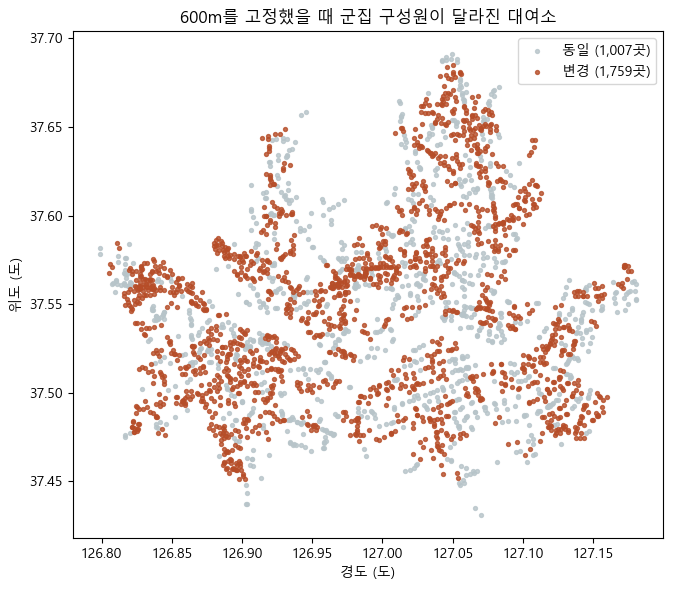

In [3]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic" if os.name=="nt" else "sans-serif"
old = stations["군집번호"]
walk600 = labels_by_limit[600]
pairs = pd.crosstab(old,walk600)
same = np.array([pairs.at[a,b]==pairs.loc[a].sum()==pairs[b].sum() for a,b in zip(old,walk600)])
fig,ax = plt.subplots(figsize=(8,6))
for mask,label,color in [(same,"동일","#b7c4c9"),(~same,"변경","#b64d28")]:
    ax.scatter(stations.loc[mask,"경도"], stations.loc[mask,"위도"], s=8, alpha=.8,
               color=color,label=f"{label} ({mask.sum():,}곳)")
ax.set(xlabel="경도 (도)", ylabel="위도 (도)", title="600m를 고정했을 때 군집 구성원이 달라진 대여소")
ax.set_aspect(1/np.cos(np.deg2rad(stations["위도"].mean())))
ax.legend()
fig.tight_layout()
plt.show()